Yuliia Chernysheva  
November 05, 2026  
CSC 2267: Linear Regression Assignment

**Import libraries**

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Task 1: Load Dataset  
Read the diamonds dataset from the Seaborn library

In [2]:
data = sns.load_dataset('diamonds')

# Task 2: Display First Five Rows
Preview the dataset and inspect the initial structure

In [3]:
display(data.head(5))

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


# Task 3: Price Correlation Heatmap
Identify correlations for the price column using a sorted, condensed heatmap

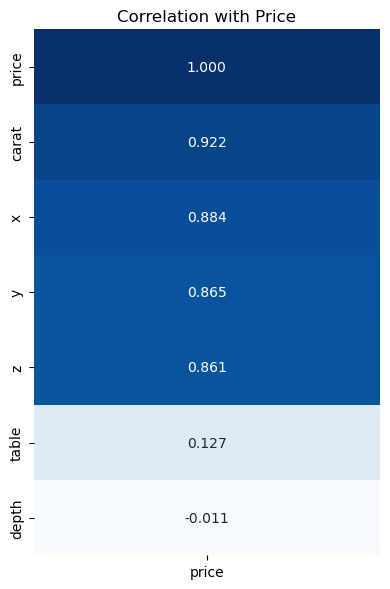

In [4]:
# Calculate correlations with the 'price' column and sort in descending order
price_corr = data[['carat','depth','table','price','x','y','z']] \
    .corr()[['price']].sort_values(by='price', ascending=False)

# Create a condensed heatmap with 3 decimal annotations and no color bar
plt.figure(figsize=(4, 6))
sns.heatmap(data=price_corr,
            annot=True,
            cmap='Blues',            
            cbar=False,
            fmt=f'.3f'
           )

plt.title('Correlation with Price')
plt.tight_layout()
plt.show()

# Task 4: Train/Test Split
Split the data using the column with the strongest correlation 'carat' into 70% train and 30% test sets

In [5]:
# Split dataset into test (30%) and training (70%) subsets
# 'carat' is selected as it has the highest correlation with 'price'
x_train, x_test, y_train, y_test = train_test_split(
    data[['carat']], data[['price']],
    test_size=0.3, random_state=42
)

# Task 5: Fit Linear Regression Model
Create a Linear Regression estimator and fit it to the training dataset

In [6]:
# Initialize the LinearRegression model, and # fit it to training data
linearModel = LinearRegression()
linearModel.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


# Task 6: Evaluate Model Score
Calculate the R-squared score of the model on the test dataset

In [7]:
# Evaluate R-squared score using the test set
test_score = linearModel.score(x_test, y_test)
print(f"Model Score (R^2): {test_score:.6f}")

Model Score (R^2): 0.848686


# Task 7: Predict Values
Predict diamond prices based on the feature values in the test dataset

In [8]:
# Generate price predictions for the test dataset
y_predicted = linearModel.predict(x_test)
display(y_predicted)

array([[-395.24226785],
       [2244.96594868],
       [ 847.20865758],
       ...,
       [9466.71195274],
       [3254.4573256 ],
       [ 847.20865758]])

# Task 8: Store Predictions in DataFrame
Construct a DataFrame containing the predicted price values

In [9]:
# Convert the predicted values into a pandas DataFrame.
predicted = pd.DataFrame(y_predicted,columns=['price_predicted'])
display(predicted.head())

,price_predicted
0,-395.242268
1,2244.965949
2,847.208658
3,1080.168206
4,9777.324684


# Task 9: Combine Test and Predicted Data
Join test features, actual test target values, and predicted prices into a single DataFrame

In [10]:
# Reset indexes to ensure correct alignment, then join the DataFrames
combined = predicted.join(
    [x_test.reset_index(drop=True),y_test.reset_index(drop=True)])

# Display the first five rows of the combined DataFrame
display(combined.head(5))

,price_predicted,carat,price
0,-395.242268,0.24,559
1,2244.965949,0.58,2201
2,847.208658,0.40,1238
3,1080.168206,0.43,1304
4,9777.324684,1.55,6901


# Task 10: Melt Actual and Predicted Prices
Unpivot the actual and predicted price columns into a long format for plotting

In [11]:
# Melt actual and predicted prices into long-form format
melted = pd.melt(combined,
                id_vars=['carat'],
                value_vars=['price','price_predicted'],
                var_name='price_type',
                value_name='price_value')

display(melted.head())

,carat,price_type,price_value
0,0.24,price,559.0
1,0.58,price,2201.0
2,0.40,price,1238.0
3,0.43,price,1304.0
4,1.55,price,6901.0


# Task 11:Plot Line Plot
Visualize actual and predicted prices across carat weights using a line plot without a confidence interval

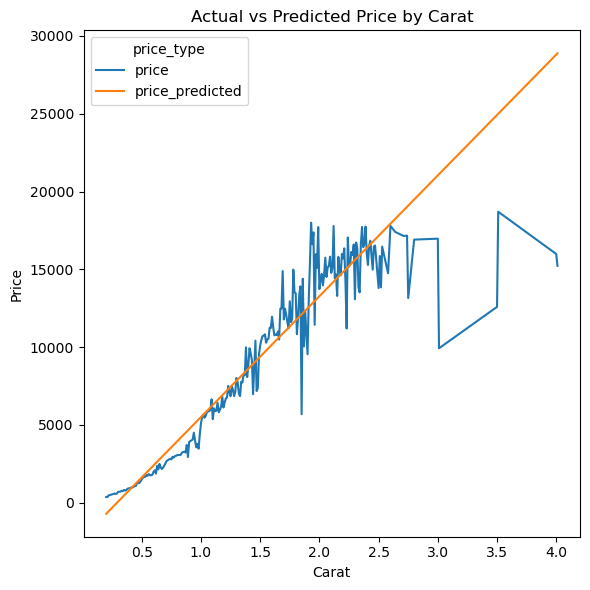

In [12]:
# Plot actual vs predicted prices using a line plot
plt.figure(figsize=(6, 6))

sns.lineplot(
    data=melted,
    x='carat',
    y='price_value',
    hue='price_type',
    errorbar=None
)
    
plt.title('Actual vs Predicted Price by Carat')
plt.xlabel('Carat')
plt.ylabel('Price')
plt.tight_layout()
plt.show()